In [1]:
import pathlib
import matplotlib.pyplot as plt
import numpy as np
from refig import refig

from zfish.invariants import compute_invariants, select_invariants
from zfish.graphs import GraphUtils, load_all_graphs_from_edgelists

plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.family"] = "Roboto"


/Users/mateljk1/Documents/projects/aplbrain/zebrafish-pencilsdown/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
CONNECTOME_EDGELIST_PATH = pathlib.Path("../data/graphs/connectomes/")
USING_RUSTWORKX = True

In [3]:
graphs = load_all_graphs_from_edgelists(
    CONNECTOME_EDGELIST_PATH, rustworkx=USING_RUSTWORKX
)
print(graphs.keys())

dict_keys(['0k', '5k', '10k', '15k', '20k', '25k', '30k', '35k', '40k', '45k', '50k'])


In [4]:
graphs = {
    identifier: {
        "graph": graph,
        "undirected_graph": GraphUtils.make_undirected(graph),
        "lcc_graph": GraphUtils.make_lcc(graph),
        "lwcc_nodes": GraphUtils.make_lwcc_nodes(graph),
    }
    for identifier, graph in graphs.items()
}


In [5]:
INVARIANTS = select_invariants("connectome")

invariants_per_graph = compute_invariants(
    graphs,
    "connectome",
    INVARIANTS,
    parallel=-1,
    progress=True,
    use_rustworkx=USING_RUSTWORKX,
)


100%|██████████| 165/165 [00:26<00:00,  6.18it/s]


In [6]:
with open("invariants_per_graph.json", "w") as f:
    import json

    json.dump(invariants_per_graph, f, indent=2)


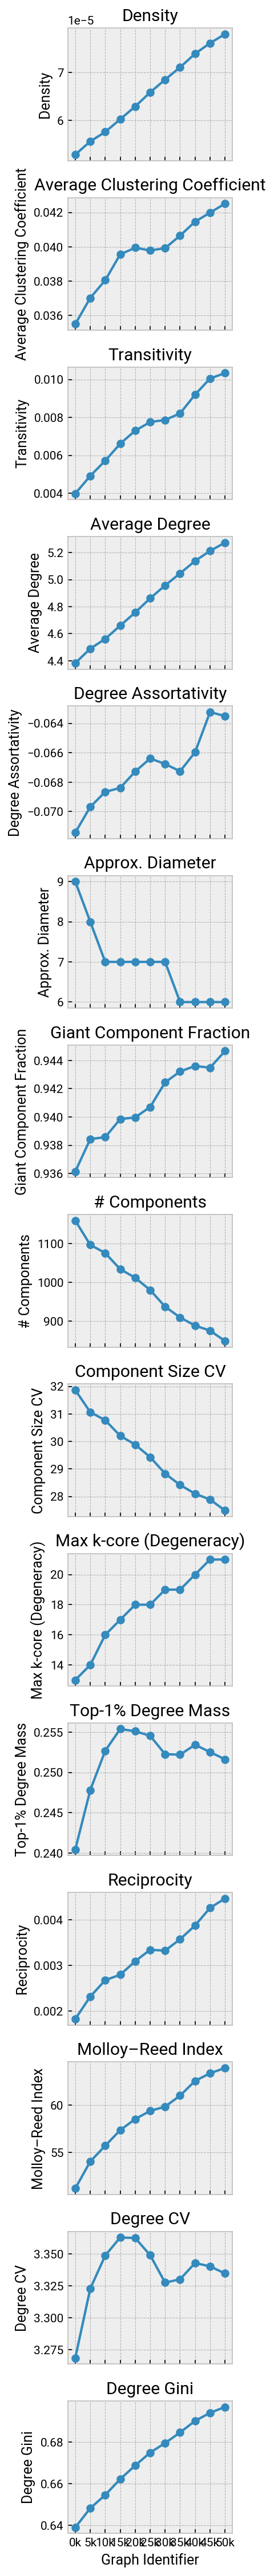

In [7]:
with plt.style.context("bmh"):
    fig, axs = plt.subplots(
        len(INVARIANTS), 1, figsize=(3, 2 * len(INVARIANTS)), dpi=150, sharex=True
    )
    for ax, (invariant_key, invariant_spec) in zip(axs, INVARIANTS.items()):
        ylabel = invariant_spec.ylabel
        graph_ids = list(invariants_per_graph[invariant_key].keys())
        values = list(invariants_per_graph[invariant_key].values())
        ax.plot(graph_ids, values, marker="o")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{ylabel}")
        ax.grid(True)
    plt.tight_layout()
    ax.set_xlabel("Graph Identifier")
    refig.savefig("invariants_per_graph.svg")
    plt.show()


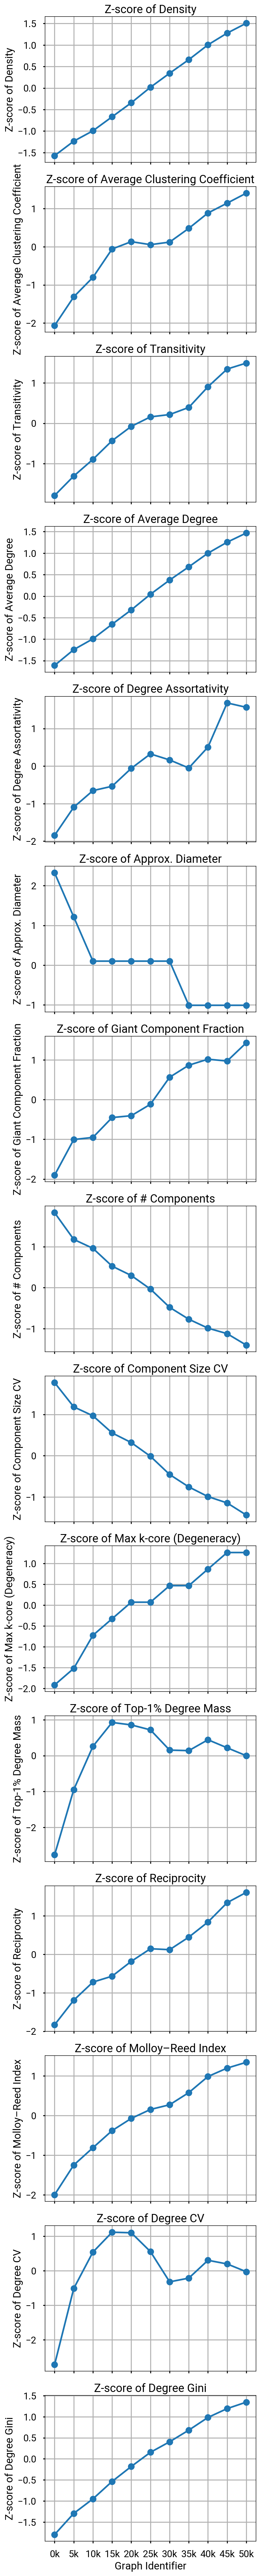

In [8]:
with plt.style.context("seaborn-v0_8-poster"):
    fig, axs = plt.subplots(
        len(INVARIANTS), 1, figsize=(6, 4 * len(INVARIANTS)), dpi=150, sharex=True
    )
    for ax, (invariant_key, invariant_spec) in zip(axs, INVARIANTS.items()):
        ylabel = invariant_spec.ylabel
        graph_ids = list(invariants_per_graph[invariant_key].keys())
        values = np.array(list(invariants_per_graph[invariant_key].values()))
        zscores = (values - np.mean(values)) / np.std(values)
        ax.plot(graph_ids, zscores, marker="o")
        ax.set_ylabel(f"Z-score of {ylabel}")
        ax.set_title(f"Z-score of {ylabel}")
        ax.grid(True)
    plt.tight_layout()
    ax.set_xlabel("Graph Identifier")
    refig.savefig("invariants_per_graph_zscores.svg")
    plt.show()


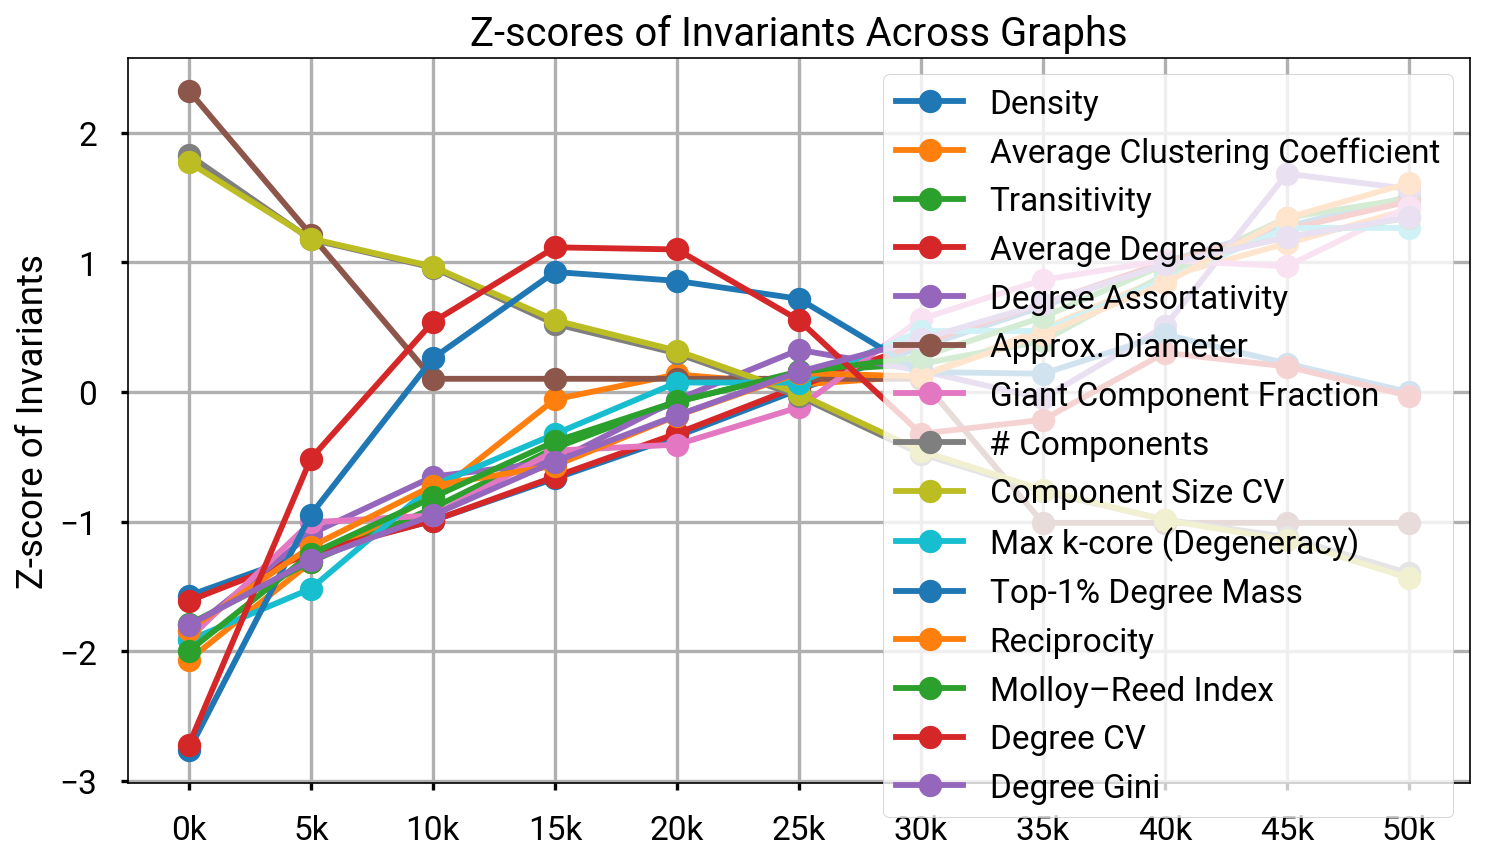

In [9]:
with plt.style.context("seaborn-v0_8-poster"):
    fig, ax = plt.subplots(figsize=(10, 6), dpi=150)
    for invariant_key, invariant_spec in INVARIANTS.items():
        ylabel = invariant_spec.ylabel
        graph_ids = list(invariants_per_graph[invariant_key].keys())
        values = np.array(list(invariants_per_graph[invariant_key].values()))
        zscores = (values - np.mean(values)) / np.std(values)
        ax.plot(graph_ids, zscores, marker="o", label=ylabel)
    ax.set_ylabel("Z-score of Invariants")
    ax.set_title("Z-scores of Invariants Across Graphs")
    ax.grid(True)
    ax.legend()
    plt.tight_layout()
    plt.show()
